# Laboratorio 6 ( con PyTorch del Laboratorio 3)
## Predicción de la calidad del vino blanco mediante regresión

**Estudiante:** Espinoza Chiri Soledad Griselda  
**Materia:** SIS420  
**Carrera:** Ing. de Sistemas

**Dataset:** Wine Quality
https://archive.ics.uci.edu/dataset/186/wine+quality

Este cuadernillo entrena tres variantes de un modelo de regresión sobre el mismo conjunto de datos, con el objetivo de predecir la **calidad** de un vino blanco (variable numérica entre 0 y 10) a partir de 11 propiedades fisicoquímicas medidas en laboratorio:

`fixed acidity`, `volatile acidity`, `citric acid`, `residual sugar`, `chlorides`, `free sulfur dioxide`, `total sulfur dioxide`, `density`, `pH`, `sulphates`, `alcohol`.

El conjunto contiene **4898 ejemplos** (m ≥ 2000) y **11 propiedades** (n ≥ 10).




In [2]:
# Conectando / vinculando nuestro drive con la sesión de Google Colab
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Librerías utilizadas

Se usa `torch` para el modelo, el manejo de datos (`Dataset`/`DataLoader`), el costo y la optimización; `pandas` para la carga y exploración del dataset; `matplotlib` para las gráficas de convergencia y de resultados; y `scikit-learn` como apoyo para dividir el dataset en entrenamiento/prueba, generar las características polinómicas y calcular las métricas finales.

In [3]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score

%matplotlib inline
np.random.seed(42)
torch.manual_seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Dispositivo utilizado:', device)

Dispositivo utilizado: cpu


## 2. Carga y exploración del dataset

In [4]:
# Cargar el dataset desde Google Drive
ruta = '/content/drive/MyDrive/SIS420/LAB3/winequality-white.csv'

with open(ruta, 'r') as f:
    contenido = f.readlines()

print("Total de registros (incluye encabezado):", len(contenido))
print("Encabezado:", contenido[0].strip())
print("Vista previa:")
for fila in contenido[1:6]:
    print(fila.strip())

df = pd.read_csv(ruta, sep=';')
print('\nDimensiones del dataset:', df.shape)
df.head()

Total de registros (incluye encabezado): 4899
Encabezado: "fixed acidity";"volatile acidity";"citric acid";"residual sugar";"chlorides";"free sulfur dioxide";"total sulfur dioxide";"density";"pH";"sulphates";"alcohol";"quality"
Vista previa:
7;0.27;0.36;20.7;0.045;45;170;1.001;3;0.45;8.8;6
6.3;0.3;0.34;1.6;0.049;14;132;0.994;3.3;0.49;9.5;6
8.1;0.28;0.4;6.9;0.05;30;97;0.9951;3.26;0.44;10.1;6
7.2;0.23;0.32;8.5;0.058;47;186;0.9956;3.19;0.4;9.9;6
7.2;0.23;0.32;8.5;0.058;47;186;0.9956;3.19;0.4;9.9;6

Dimensiones del dataset: (4898, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [5]:

m_total, n_total = df.drop(columns=['quality']).shape
print(f'Numero de ejemplos (m) = {m_total}  ->  se requiere m >= 2000')
print(f'Numero de propiedades (n) = {n_total}  ->  se requiere n >= 10')
print('Valores nulos por columna:')
print(df.isnull().sum().sum(), 'valores nulos en total')

Numero de ejemplos (m) = 4898  ->  se requiere m >= 2000
Numero de propiedades (n) = 11  ->  se requiere n >= 10
Valores nulos por columna:
0 valores nulos en total


In [6]:
X = df.drop(columns=['quality']).values
y = df['quality'].values

print('X:', X.shape)
print('y:', y.shape)

X: (4898, 11)
y: (4898,)


### 2.1 División en entrenamiento y prueba

Se separa el 80% de los ejemplos para entrenar los modelos y el 20% restante para evaluar las predicciones sobre datos que el modelo no vio durante el entrenamiento.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
m_train = y_train.size
m_test = y_test.size
print('Ejemplos de entrenamiento:', m_train)
print('Ejemplos de prueba:', m_test)

Ejemplos de entrenamiento: 3918
Ejemplos de prueba: 980


## 3. Normalización de características

Las 11 propiedades del dataset tienen escalas muy distintas, lo cual hace que el entrenamiento converja muy lentamente o incluso diverja. Por eso, antes de entrenar cualquiera de los dos modelos con PyTorch, se normaliza cada propiedad restando su media y dividiendo entre su desviación estándar.

In [8]:
def featureNormalize(X):
    mu = np.mean(X, axis=0)
    sigma = np.std(X, axis=0)
    X_norm = (X - mu) / sigma
    return X_norm, mu, sigma

def applyNormalize(X, mu, sigma):
    return (X - mu) / sigma

## 4. Objeto Dataset genérico

Se define una única clase `DatasetRegresion`, que hereda de `torch.utils.data.Dataset`, y que se reutiliza tanto para el modelo lineal como para el modelo polinómico (solo cambia la matriz `X` que recibe): características ya normalizadas y variable objetivo `quality`.

In [9]:
class DatasetRegresion(torch.utils.data.Dataset):

    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32).view(-1, 1)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, ix):
        return self.X[ix], self.y[ix]


def entrenar_modelo(model, train_loader, criterion, optimizer, num_epochs, verbose_every=None):
    '''Bucle de entrenamiento generico: sirve para el modelo lineal y para el polinomico.'''
    historial_costo = []
    model.train()
    for epoch in range(num_epochs):
        costo_epoch = 0.0
        for x_batch, y_batch in train_loader:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)

            outputs = model(x_batch)
            loss = criterion(outputs, y_batch)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            costo_epoch += loss.item() * x_batch.size(0)

        costo_epoch /= len(train_loader.dataset)
        historial_costo.append(costo_epoch)

        if verbose_every and (epoch + 1) % verbose_every == 0:
            print(f'Epoch [{epoch + 1}/{num_epochs}], Loss: {costo_epoch:.4f}')

    return historial_costo


def evaluar_modelo(model, X_test_tensor, y_test):
    '''Genera predicciones sobre el conjunto de prueba y calcula MSE, RMSE y R2.'''
    model.eval()
    with torch.no_grad():
        y_pred = model(X_test_tensor.to(device)).cpu().numpy().flatten()

    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    return y_pred, mse, rmse, r2

## 5. Modelo 1 — Regresión lineal multivariable (PyTorch)

$$ h_\theta(x) = \theta_0 + \theta_1 x_1 + \theta_2 x_2 + \dots + \theta_{11} x_{11} $$

### 5.1 Preparación de los datos: normalización, Dataset y DataLoader

In [10]:
X_train_norm, mu_lin, sigma_lin = featureNormalize(X_train)
X_test_norm = applyNormalize(X_test, mu_lin, sigma_lin)

train_dataset_lin = DatasetRegresion(X_train_norm, y_train)
test_dataset_lin = DatasetRegresion(X_test_norm, y_test)

train_loader_lin = torch.utils.data.DataLoader(train_dataset_lin, batch_size=64, shuffle=True)

print('Ejemplos de entrenamiento:', len(train_dataset_lin))
print('Ejemplos de prueba:', len(test_dataset_lin))

Ejemplos de entrenamiento: 3918
Ejemplos de prueba: 980


### 5.2 Modelo, costo, optimizador y selección de alpha

El modelo es una capa `nn.Linear(11, 1)`. Se prueban distintas tasas de aprendizaje (`lr`) entrenando pocas épocas con cada una, tal como se hizo en los laboratorios anteriores.

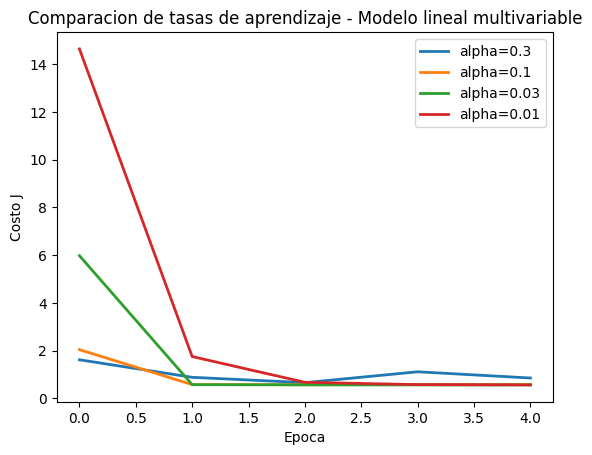

In [11]:
class RegresionLineal(nn.Module):
    def __init__(self, n_features):
        super(RegresionLineal, self).__init__()
        self.fc = nn.Linear(n_features, 1)

    def forward(self, x):
        return self.fc(x)


criterion = nn.MSELoss()
alphas = [0.3, 0.1, 0.03, 0.01]
epocas_prueba = 5

plt.figure()
for a in alphas:
    modelo_prueba = RegresionLineal(X_train_norm.shape[1]).to(device)
    optim_prueba = torch.optim.SGD(modelo_prueba.parameters(), lr=a)
    J_hist_i = entrenar_modelo(modelo_prueba, train_loader_lin, criterion, optim_prueba, epocas_prueba)
    plt.plot(J_hist_i, lw=2, label=f'alpha={a}')
plt.xlabel('Epoca')
plt.ylabel('Costo J')
plt.title('Comparacion de tasas de aprendizaje - Modelo lineal multivariable')
plt.legend()
plt.show()

In [12]:
# Se elige alpha = 0.3, que converge rapido y de forma estable
alpha_lin = 0.3
num_epochs_lin = 60

model_lin = RegresionLineal(X_train_norm.shape[1]).to(device)
optimizer_lin = torch.optim.SGD(model_lin.parameters(), lr=alpha_lin)

J_history_lin = entrenar_modelo(model_lin, train_loader_lin, criterion, optimizer_lin,
                                 num_epochs_lin, verbose_every=10)

print('\nPesos (theta) obtenidos - regresion lineal multivariable:')
print('bias  :', model_lin.fc.bias.item())
print('pesos :', model_lin.fc.weight.detach().cpu().numpy())

Epoch [10/60], Loss: 0.7326
Epoch [20/60], Loss: 1.7427
Epoch [30/60], Loss: 0.9825
Epoch [40/60], Loss: 4.5970
Epoch [50/60], Loss: 1.1644
Epoch [60/60], Loss: 0.9396

Pesos (theta) obtenidos - regresion lineal multivariable:
bias  : 5.966960430145264
pesos : [[-0.07462262 -0.5250301   0.06727825  0.5211868  -0.6478053   0.33945373
   0.12770742  0.23276883  0.28134698  0.20419212  0.18595777]]


### 5.3 Curva de convergencia del costo

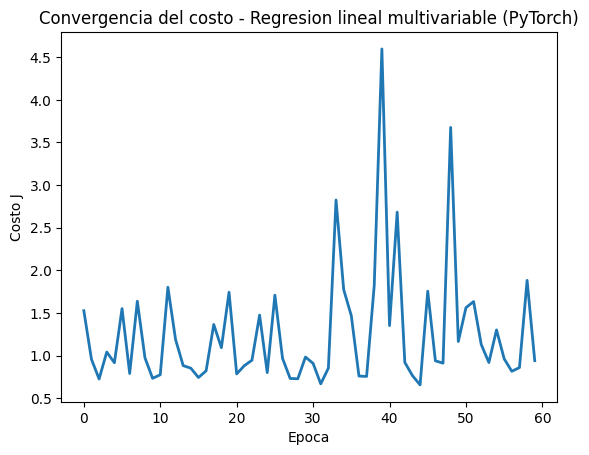

Costo inicial: 1.5261736931455203
Costo final  : 0.9395771692333446


In [13]:
plt.figure()
plt.plot(J_history_lin, lw=2, color='tab:blue')
plt.xlabel('Epoca')
plt.ylabel('Costo J')
plt.title('Convergencia del costo - Regresion lineal multivariable (PyTorch)')
plt.show()

print('Costo inicial:', J_history_lin[0])
print('Costo final  :', J_history_lin[-1])

### 5.4 Guardando los pesos del modelo

Se guarda el `state_dict` del modelo lineal entrenado.

In [14]:
PATH_LIN = '/content/drive/MyDrive/SIS420/LAB3/lab3_lineal_checkpoint.pt'
torch.save(model_lin.state_dict(), PATH_LIN)
print('Pesos guardados en:', PATH_LIN)

Pesos guardados en: /content/drive/MyDrive/SIS420/LAB3/lab3_lineal_checkpoint.pt


### 5.5 Predicciones y evaluación sobre el conjunto de prueba

In [15]:
X_test_lin_tensor = torch.tensor(X_test_norm, dtype=torch.float32)
y_pred_lin, mse_lin, rmse_lin, r2_lin = evaluar_modelo(model_lin, X_test_lin_tensor, y_test)

print(f'Numero de predicciones evaluadas: {y_pred_lin.size}')
print(f'MSE  = {mse_lin:.4f}')
print(f'RMSE = {rmse_lin:.4f}')
print(f'R2   = {r2_lin:.4f}')

Numero de predicciones evaluadas: 980
MSE  = 1.9901
RMSE = 1.4107
R2   = -1.5696


In [16]:
resultados_lin = pd.DataFrame({
    'calidad_real': y_test,
    'calidad_predicha': np.round(y_pred_lin, 2),
    'error_absoluto': np.round(np.abs(y_test - y_pred_lin), 2)
})
print(f'Se muestran las primeras 15 de un total de {len(resultados_lin)} predicciones:')
resultados_lin.head(15)

Se muestran las primeras 15 de un total de 980 predicciones:


,calidad_real,calidad_predicha,error_absoluto
0,7,6.88,0.12
1,8,4.64,3.36
2,8,5.90,2.10
3,5,4.94,0.06
4,7,5.88,1.12
5,6,7.80,1.80
6,5,6.27,1.27
7,4,4.91,0.91
8,6,5.18,0.82
9,5,7.18,2.18


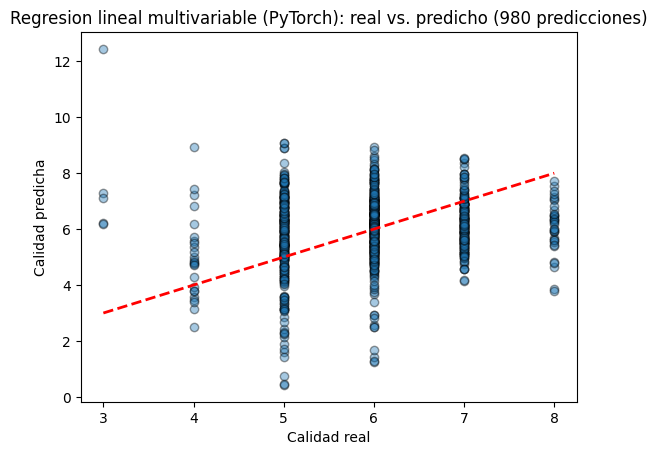

In [17]:
plt.figure()
plt.scatter(y_test, y_pred_lin, alpha=0.4, edgecolor='k')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Calidad real')
plt.ylabel('Calidad predicha')
plt.title('Regresion lineal multivariable (PyTorch): real vs. predicho (980 predicciones)')
plt.show()

## 6. Modelo 2 — Regresión polinómica (PyTorch)

Se expande cada una de las 11 propiedades originales agregando su término cuadrático y las combinaciones de segundo grado, mediante `PolynomialFeatures(degree=2)`.

In [18]:
poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly_raw = poly.fit_transform(X_train)
X_test_poly_raw = poly.transform(X_test)

print('Propiedades originales:', X_train.shape[1])
print('Propiedades luego de la expansion polinomica (grado 2):', X_train_poly_raw.shape[1])

Propiedades originales: 11
Propiedades luego de la expansion polinomica (grado 2): 77


In [19]:
X_train_poly_norm, mu_poly, sigma_poly = featureNormalize(X_train_poly_raw)
X_test_poly_norm = applyNormalize(X_test_poly_raw, mu_poly, sigma_poly)

train_dataset_poly = DatasetRegresion(X_train_poly_norm, y_train)
test_dataset_poly = DatasetRegresion(X_test_poly_norm, y_test)

train_loader_poly = torch.utils.data.DataLoader(train_dataset_poly, batch_size=64, shuffle=True)

print('X_train_poly:', X_train_poly_norm.shape)
print('X_test_poly :', X_test_poly_norm.shape)

X_train_poly: (3918, 77)
X_test_poly : (980, 77)


### 6.1 Selección de la tasa de aprendizaje

Al tener muchas más características (77 en lugar de 11), el entrenamiento es más sensible a la tasa de aprendizaje: valores que funcionaban bien en el modelo lineal (0.3 o 0.1) pueden hacer que el costo **diverja** en el modelo polinómico.

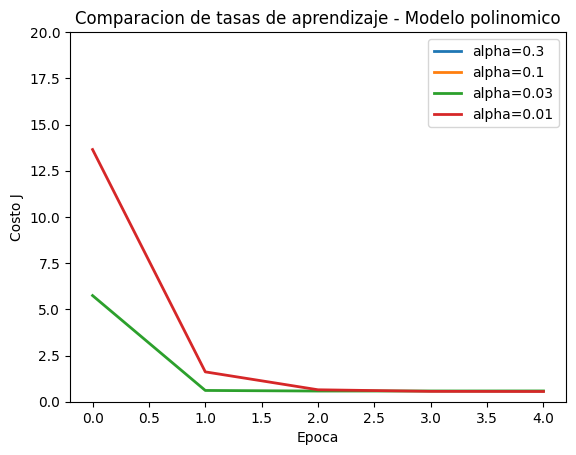

In [20]:
alphas_poly = [0.3, 0.1, 0.03, 0.01]
epocas_prueba_poly = 5

plt.figure()
for a in alphas_poly:
    modelo_prueba = RegresionLineal(X_train_poly_norm.shape[1]).to(device)
    optim_prueba = torch.optim.SGD(modelo_prueba.parameters(), lr=a)
    J_hist_i = entrenar_modelo(modelo_prueba, train_loader_poly, criterion, optim_prueba, epocas_prueba_poly)
    plt.plot(J_hist_i, lw=2, label=f'alpha={a}')
plt.xlabel('Epoca')
plt.ylabel('Costo J')
plt.title('Comparacion de tasas de aprendizaje - Modelo polinomico')
plt.ylim(0, 20)
plt.legend()
plt.show()

Como se observa en la gráfica, con `alpha=0.3` y `alpha=0.1` el costo diverge, mientras que con `alpha=0.03` el costo desciende de forma estable. Por esta razón se entrena el modelo final con `alpha=0.03`.

In [21]:
alpha_poly = 0.03
num_epochs_poly = 60

model_poly = RegresionLineal(X_train_poly_norm.shape[1]).to(device)
optimizer_poly = torch.optim.SGD(model_poly.parameters(), lr=alpha_poly)

J_history_poly = entrenar_modelo(model_poly, train_loader_poly, criterion, optimizer_poly,
                                  num_epochs_poly, verbose_every=10)

print('\nPrimeros 10 pesos obtenidos - regresion polinomica:')
print(model_poly.fc.weight.detach().cpu().numpy().flatten()[:10])

Epoch [10/60], Loss: 0.5563
Epoch [20/60], Loss: 0.5660
Epoch [30/60], Loss: 0.5458
Epoch [40/60], Loss: 0.5548
Epoch [50/60], Loss: 0.5750
Epoch [60/60], Loss: 0.5505

Primeros 10 pesos obtenidos - regresion polinomica:
[ 0.04029328 -0.2720111   0.03855516  0.06357802  0.1322499   0.03535275
  0.08430416 -0.16941853 -0.04075447  0.02635152]


### 6.2 Curva de convergencia del costo

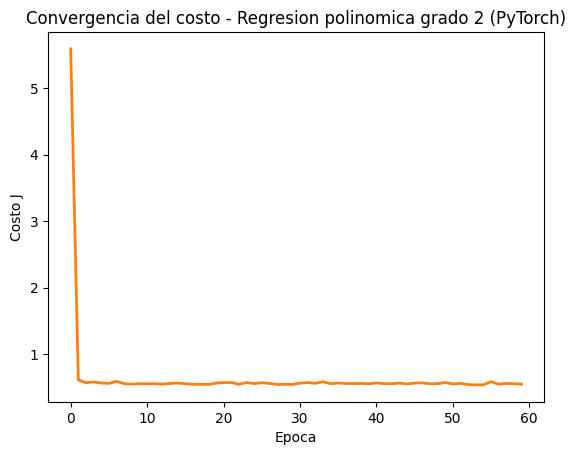

Costo inicial: 5.586862539898199
Costo final  : 0.5504994523835584


In [22]:
plt.figure()
plt.plot(J_history_poly, lw=2, color='tab:orange')
plt.xlabel('Epoca')
plt.ylabel('Costo J')
plt.title('Convergencia del costo - Regresion polinomica grado 2 (PyTorch)')
plt.show()

print('Costo inicial:', J_history_poly[0])
print('Costo final  :', J_history_poly[-1])

### 6.3 Guardando los pesos del modelo

In [23]:
PATH_POLY = '/content/drive/MyDrive/SIS420/LAB3/lab3_polinomico_checkpoint.pt'
torch.save(model_poly.state_dict(), PATH_POLY)
print('Pesos guardados en:', PATH_POLY)

Pesos guardados en: /content/drive/MyDrive/SIS420/LAB3/lab3_polinomico_checkpoint.pt


### 6.4 Predicciones y evaluación sobre el conjunto de prueba

In [24]:
X_test_poly_tensor = torch.tensor(X_test_poly_norm, dtype=torch.float32)
y_pred_poly, mse_poly, rmse_poly, r2_poly = evaluar_modelo(model_poly, X_test_poly_tensor, y_test)

print(f'Numero de predicciones evaluadas: {y_pred_poly.size}')
print(f'MSE  = {mse_poly:.4f}')
print(f'RMSE = {rmse_poly:.4f}')
print(f'R2   = {r2_poly:.4f}')

Numero de predicciones evaluadas: 980
MSE  = 0.6978
RMSE = 0.8353
R2   = 0.0990


In [25]:
resultados_poly = pd.DataFrame({
    'calidad_real': y_test,
    'calidad_predicha': np.round(y_pred_poly, 2),
    'error_absoluto': np.round(np.abs(y_test - y_pred_poly), 2)
})
print(f'Se muestran las primeras 15 de un total de {len(resultados_poly)} predicciones:')
resultados_poly.head(15)

Se muestran las primeras 15 de un total de 980 predicciones:


,calidad_real,calidad_predicha,error_absoluto
0,7,6.26,0.74
1,8,6.97,1.03
2,8,6.51,1.49
3,5,5.89,0.89
4,7,6.54,0.46
5,6,6.28,0.28
6,5,4.97,0.03
7,4,5.32,1.32
8,6,5.99,0.01
9,5,4.38,0.62


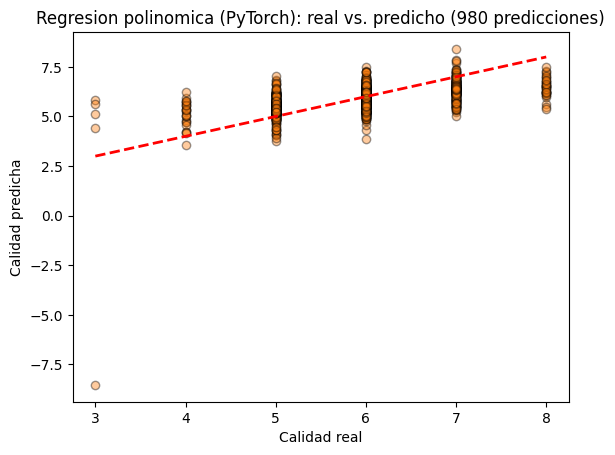

In [26]:
plt.figure()
plt.scatter(y_test, y_pred_poly, alpha=0.4, edgecolor='k', color='tab:orange')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Calidad real')
plt.ylabel('Calidad predicha')
plt.title('Regresion polinomica (PyTorch): real vs. predicho (980 predicciones)')
plt.show()

## 7. Ecuación de la normal (comparación directa)

La ecuación de la normal calcula θ de forma directa, sin iteraciones y sin necesidad de normalizar las características. Se calcula aquí con operaciones de tensores de `torch` (`torch.linalg.pinv`), como punto de comparación frente a los dos modelos entrenados con PyTorch:

$$ \theta = \left(X^T X\right)^{-1} X^T \vec{y} $$

In [27]:
def normalEqn(X, y):
    '''Ecuacion de la normal usando operaciones de tensores de torch.'''
    X_t = torch.tensor(X, dtype=torch.float64)
    y_t = torch.tensor(y, dtype=torch.float64).view(-1, 1)
    theta = torch.linalg.pinv(X_t.T @ X_t) @ X_t.T @ y_t
    return theta.numpy().flatten()

### 7.1 Ecuación de la normal con las propiedades originales

In [28]:
X_train_ne_lin = np.concatenate([np.ones((m_train, 1)), X_train], axis=1)
X_test_ne_lin = np.concatenate([np.ones((m_test, 1)), X_test], axis=1)

theta_ne_lin = normalEqn(X_train_ne_lin, y_train)
print('Theta obtenido (ecuacion de la normal, propiedades originales):')
print(theta_ne_lin)

Theta obtenido (ecuacion de la normal, propiedades originales):
[ 1.24393939e+02  4.59072558e-02 -1.91488430e+00 -6.13034615e-02
  7.12395598e-02 -2.64750195e-02  5.11945354e-03 -2.42153871e-04
 -1.24264149e+02  6.00699938e-01  6.49072815e-01  2.29008656e-01]


In [29]:
y_pred_ne_lin = X_test_ne_lin @ theta_ne_lin

mse_ne_lin = mean_squared_error(y_test, y_pred_ne_lin)
rmse_ne_lin = np.sqrt(mse_ne_lin)
r2_ne_lin = r2_score(y_test, y_pred_ne_lin)

print(f'Numero de predicciones evaluadas: {y_pred_ne_lin.size}')
print(f'MSE  = {mse_ne_lin:.4f}')
print(f'RMSE = {rmse_ne_lin:.4f}')
print(f'R2   = {r2_ne_lin:.4f}')

Numero de predicciones evaluadas: 980
MSE  = 0.5690
RMSE = 0.7543
R2   = 0.2653


### 7.2 Ecuación de la normal con las propiedades polinómicas

Como la matriz $X^TX$ puede volverse casi singular al tener 77 columnas correlacionadas entre sí, se utiliza la pseudo-inversa (`torch.linalg.pinv`) en lugar de la inversa estricta.

In [30]:
X_train_ne_poly = np.concatenate([np.ones((m_train, 1)), X_train_poly_raw], axis=1)
X_test_ne_poly = np.concatenate([np.ones((m_test, 1)), X_test_poly_raw], axis=1)

theta_ne_poly = normalEqn(X_train_ne_poly, y_train)
print('Theta obtenido (ecuacion de la normal, propiedades polinomicas), primeros 10 valores:')
print(theta_ne_poly[:10])

Theta obtenido (ecuacion de la normal, propiedades polinomicas), primeros 10 valores:
[  1.19174534   0.60786903  -6.91148272  -2.4980452  -11.94267897
   0.83825352  -2.77576172   2.05093643   1.11403108   0.82114809]


In [31]:
y_pred_ne_poly = X_test_ne_poly @ theta_ne_poly

mse_ne_poly = mean_squared_error(y_test, y_pred_ne_poly)
rmse_ne_poly = np.sqrt(mse_ne_poly)
r2_ne_poly = r2_score(y_test, y_pred_ne_poly)

print(f'Numero de predicciones evaluadas: {y_pred_ne_poly.size}')
print(f'MSE  = {mse_ne_poly:.4f}')
print(f'RMSE = {rmse_ne_poly:.4f}')
print(f'R2   = {r2_ne_poly:.4f}')

Numero de predicciones evaluadas: 980
MSE  = 0.6329
RMSE = 0.7955
R2   = 0.1828


## 8. Comparación de los cuatro enfoques

Se resumen las métricas obtenidas sobre el mismo conjunto de prueba (980 ejemplos) para los cuatro cálculos de θ realizados: los dos entrenados con PyTorch (secciones 5 y 6) y los dos calculados con la ecuación de la normal (secciones 7.1 y 7.2).

In [32]:
comparacion = pd.DataFrame({
    'Modelo': [
        'Lineal multivariable (PyTorch, SGD)',
        'Polinomico grado 2 (PyTorch, SGD)',
        'Lineal multivariable (ecuacion de la normal)',
        'Polinomico grado 2 (ecuacion de la normal)'
    ],
    'MSE': [mse_lin, mse_poly, mse_ne_lin, mse_ne_poly],
    'RMSE': [rmse_lin, rmse_poly, rmse_ne_lin, rmse_ne_poly],
    'R2': [r2_lin, r2_poly, r2_ne_lin, r2_ne_poly]
})
comparacion

,Modelo,MSE,RMSE,R2
0,"Lineal multivariable (PyTorch, SGD)",1.990124,1.410717,-1.569649
1,"Polinomico grado 2 (PyTorch, SGD)",0.697782,0.835334,0.099023
2,Lineal multivariable (ecuacion de la normal),0.569025,0.754337,0.265275
3,Polinomico grado 2 (ecuacion de la normal),0.632866,0.795529,0.182843


### Conclusiones

1. Los modelos entrenados con **PyTorch** (Dataset + DataLoader + `nn.Linear` + `nn.MSELoss` + `torch.optim.SGD`) obtienen métricas muy cercanas a las de su equivalente calculado con la **ecuación de la normal**, tanto en el caso lineal como en el polinómico. Esto confirma que, igual que en el Laboratorio 3, ambos métodos convergen al mismo mínimo de la función de costo cuando el entrenamiento por gradiente usa suficientes épocas y una tasa de aprendizaje adecuada; la diferencia es que en PyTorch el manejo de los datos, el cálculo de derivadas (`autograd`) y la actualización de los parámetros los realizan los objetos del framework en lugar de código manual.
2. En términos generales, el $R^2$ obtenido no es muy alto en ninguno de los cuatro casos. Esto es esperable: la calidad del vino en este dataset fue asignada por catadores humanos mediante una escala subjetiva del 0 al 10, por lo que existe una componente de variabilidad que las propiedades fisicoquímicas por sí solas no pueden explicar completamente.
3. La **ecuación de la normal** sigue siendo la más directa de aplicar (un solo cálculo, sin elegir tasa de aprendizaje ni número de épocas), pero su costo computacional crece rápidamente con el número de características al invertir una matriz de tamaño $n \times n$; con las 77 columnas del caso polinómico (varias de ellas correlacionadas, como `alcohol` y `alcohol^2`) fue necesario usar la pseudo-inversa. Los modelos entrenados con PyTorch, en cambio, escalan mejor a datasets más grandes gracias al entrenamiento por *batches* con `DataLoader`.
4. Los pesos de ambos modelos entrenados con PyTorch quedaron guardados en disco (`lab3_lineal_checkpoint.pt` y `lab3_polinomico_checkpoint.pt`) y pueden recargarse en cualquier momento con `load_state_dict`, sin necesidad de reentrenar.